# Assignment 4

## 1. Environment check and dependencies

In [1]:
import sys, platform, importlib.util
print('Python:', sys.version.split()[0], '| OS:', platform.system())
for p in ['torch','transformers','huggingface_hub','pandas','numpy','matplotlib','scipy','sklearn']:
    print(p, bool(importlib.util.find_spec(p)))


Python: 3.12.4 | OS: Windows
torch True
transformers True
huggingface_hub True
pandas True
numpy True
matplotlib True
scipy True
sklearn True


In [3]:
%pip install transformers huggingface_hub

  Using cached transformers-5.22.2-py3-none-any.whl.metadata (31 kB)
Using cached transformers-5.22.2-py3-none-any.whl (13.1 MB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip show torch transformers numpy pandas

Name: torch
Version: 2.15.0
Summary: Tensors and Dynamic neural networks in Python with strong GPU acceleration
Home-page: https://pytorch.org
Author: 
Author-email: PyTorch Team <packages@pytorch.org>
License-Expression: Apache-2.0 AND Apache-2.0 WITH LLVM-exception AND BSD-2-Clause AND BSD-3-Clause AND BSL-1.0 AND ISC AND MIT AND Zlib
Location: C:\Users\User\PycharmProjects\JupyterProject5\.venv\Lib\site-packages
Requires: filelock, fsspec, jinja2, networkx, setuptools, sympy, typing-extensions
Required-by: 
---
Name: numpy
Version: 2.5.4
Summary: Fundamental package for array computing in Python
Home-page: https://numpy.org
Author: Travis E. Oliphant et al.
Author-email: 
License-Expression: BSD-3-Clause AND 0BSD AND MIT AND Zlib AND CC0-1.0
Location: C:\Users\User\PycharmProjects\JupyterProject5\.venv\Lib\site-packages
Requires: 
Required-by: contourpy, matplotlib, pandas, scikit-learn, scipy
---
Name: pandas
Version: 3.1.1
Summary: Powerful data structures for data analysis, time 

In [5]:
import torch, transformers, pandas as pd, numpy as np, scipy, matplotlib
print('PyTorch',torch.__version__,'Transformers',transformers.__version__)
print('CUDA:',torch.cuda.is_available())


PyTorch 2.15.0+cpu Transformers 5.22.2
CUDA: False


In [4]:
import torch
import transformers

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

C:\Users\User\PycharmProjects\JupyterProject5\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.15.0+cpu
Transformers: 5.22.2
CUDA available: False


In [6]:
import importlib.util

packages = [
    "scipy",
    "sklearn",
    "matplotlib",
    "tqdm",
    "huggingface_hub"
]

for package in packages:
    print(package, "OK" if importlib.util.find_spec(package) else "MISSING")

scipy OK
sklearn OK
matplotlib OK
tqdm OK
huggingface_hub OK


## 2. Fixed protocol and paths

In [7]:
from pathlib import Path
import json, gzip, re, unicodedata, random, collections, hashlib, subprocess, time, os, sys, platform
from datetime import datetime, timezone
from scipy.stats import fisher_exact
from sklearn.feature_extraction.text import TfidfVectorizer
from tqdm.auto import tqdm

SEED=42
DATA_COMMIT='ab8684a667109f2a7345f4f89ab3b123e8d78e1f'
MODEL='Qwen/Qwen2.5-1.5B-Instruct'
# Pinned model revision recorded in Assignment 3; verify accessible before final freeze.
MODEL_REVISION='989aa7980e4cf806f80c7fef2b1adb7bc71aa306'
SYSTEM='Сұраққа тек берілген мәтінге сүйеніп жауап бер. Мәтіннен қысқа жауап үзіндісін ғана жаз. Түсіндірме қоспа.'
N_PER_GROUP=100
PROJECT=Path.cwd()
DATA=PROJECT/'kazqad_source'
PILOT_SELECTED=PROJECT/'pilot_selected.json'  # COPY Assignment 3 results/selected.json here if available
OUT=PROJECT/'assignment4_final'
print('Working folder:',PROJECT)
print('Pilot exclusion file present:',PILOT_SELECTED.exists())


Working folder: C:\Users\User\Downloads
Pilot exclusion file present: False


In [9]:
from pathlib import Path
import subprocess
import sys
import shutil

PROJECT = Path.cwd()
DATA = PROJECT / "kazqad_source"

# Download the original KazQAD dataset
if not (DATA / ".git").exists():
    subprocess.run([
        "git", "clone",
        "https://github.com/IS2AI/KazQAD.git",
        str(DATA)
    ], check=True)

# Use the same dataset version as Assignment 3
subprocess.run([
    "git", "-C", str(DATA),
    "checkout",
    "ab8684a667109f2a7345f4f89ab3b123e8d78e1f"
], check=True)

# Generate the deterministic pilot selection
subprocess.run([
    sys.executable, "qa_compare.py",
    "prepare",
    "--data", str(DATA),
    "--n", "5",
    "--out", str(PROJECT / "reconstructed_pilot")
], check=True)

source = PROJECT / "reconstructed_pilot" / "selected.json"
destination = PROJECT / "pilot_selected.json"

shutil.copyfile(source, destination)

print("File created:", destination)
print("File exists:", destination.exists())

File created: C:\Users\User\Downloads\pilot_selected.json
File exists: True


In [10]:
import json
from pathlib import Path
from collections import Counter

pilot_file = Path("pilot_selected.json")

with open(pilot_file, "r", encoding="utf-8") as f:
    pilot_data = json.load(f)

print("Total questions:", len(pilot_data))
print("Groups:", Counter(row["group"] for row in pilot_data))
print("First question:", pilot_data[0]["question"])

Total questions: 10
Groups: Counter({'original': 5, 'translated': 5})
First question: Ақша құнының төмендеуі немен байланысты?


In [12]:
import subprocess
import sys
from pathlib import Path

PROJECT = Path.cwd()

subprocess.run([
    sys.executable,
    str(PROJECT / "qa_compare.py"),
    "prepare",
    "--data", str(PROJECT / "kazqad_source"),
    "--n", "100",
    "--exclude-sample", str(PROJECT / "pilot_selected.json"),
    "--out", str(PROJECT / "assignment4_final")
], check=True)

print("Final dataset prepared!")

Final dataset prepared!


## 3. Download fixed source dataset (Git required)

In [13]:
if not DATA.exists():
    print('Cloning KazQAD — internet and Git required...')
    subprocess.run(['git','clone','https://github.com/IS2AI/KazQAD.git',str(DATA)],check=True)
subprocess.run(['git','-C',str(DATA),'checkout',DATA_COMMIT],check=True)
actual=subprocess.check_output(['git','-C',str(DATA),'rev-parse','HEAD'],text=True).strip()
assert actual==DATA_COMMIT
print('Dataset revision:',actual)


Dataset revision: ab8684a667109f2a7345f4f89ab3b123e8d78e1f


## 4. Dataset preparation (matches Assignment 3 rules)

In [14]:
def norm(text):
    text=unicodedata.normalize('NFC',str(text)).casefold()
    return ' '.join(''.join(' ' if unicodedata.category(c).startswith('P') else c for c in text).split())

def sha256(path):
    h=hashlib.sha256()
    with open(path,'rb') as f:
        for block in iter(lambda:f.read(1024*1024),b''): h.update(block)
    return h.hexdigest()

def load_group(path, group):
    opener=gzip.open if str(path).endswith('.gz') else open
    rows=[]; counts=collections.Counter(); seen=set()
    with opener(path,'rt',encoding='utf-8') as f:
        for line_no,line in enumerate(f,1):
            counts['source_records']+=1
            d=json.loads(line); q=d.get('question',''); ctx=d.get('context','')
            ans=d.get('answers',{})
            refs=ans.get('text',[]) if isinstance(ans,dict) else []
            if isinstance(refs,str):refs=[refs]
            if not isinstance(q,str) or not isinstance(ctx,str) or not norm(q) or not norm(ctx) or not isinstance(refs,list):
                counts['missing_fields']+=1; continue
            refs=[a for a in refs if isinstance(a,str) and norm(a)]
            if not refs:counts['missing_fields']+=1;continue
            refs=[a for a in refs if norm(a) in norm(ctx)]
            if not refs:counts['unsupported_reference']+=1;continue
            key=norm(q)
            if key in seen:counts['duplicate_question']+=1;continue
            seen.add(key) # same order as Assignment 3: deduplicate before passage filter
            length=len(ctx.split())
            if not 30<=length<=250:counts['passage_length_excluded']+=1;continue
            kind='number' if any(c.isdigit() for c in refs[0]) else ('short' if len(refs[0].split())<=3 else 'long')
            rows.append(dict(group=group,id=str(d.get('id',line_no)),source_line=line_no,
                question=q,context=ctx,references=refs,answer_type=kind,
                question_words=len(q.split()),context_words=length,stratum=f'{length//50}:{kind}'))
    counts['eligible']=len(rows)
    return rows,dict(counts)

paths={'original':DATA/'data/reading-comprehension/kazqad-reading-comprehension-v1.0-kk-test.jsonl',
       'translated':DATA/'data/supplementary/nq-translate-kk/nq-reading-comprehension-translate-kk.jsonl.gz'}
for path in paths.values():assert path.exists(),f'Missing source file: {path}'
groups={};audit={}
for g,p in paths.items():
    groups[g],audit[g]=load_group(p,g)
    audit[g]['sha256']=sha256(p)
shared={norm(r['question']) for r in groups['original']} & {norm(r['question']) for r in groups['translated']}
for g in groups:groups[g]=[r for r in groups[g] if norm(r['question']) not in shared]
print(pd.DataFrame(audit).T)


           source_records duplicate_question passage_length_excluded eligible  \
original             2713                792                     102     1819   
translated          61606                515                    6699    54389   

                                                       sha256 missing_fields  
original    fe9bea821245c02d4550f0813c3c3d7603617dbb0ab230...            NaN  
translated  45ab687fef15758a91829d3bbf1f2e20e7d16cb4033b54...              3  


In [15]:
assert PILOT_SELECTED.exists(), ('Copy Assignment 3 results/selected.json to pilot_selected.json '
                                 'in the notebook folder before final selection.')
pilot=json.loads(PILOT_SELECTED.read_text(encoding='utf-8'))
excluded={norm(r['question']) for r in pilot}
for g in groups:groups[g]=[r for r in groups[g] if norm(r['question']) not in excluded]
by={g:collections.defaultdict(list) for g in groups}
for g in groups:
    for r in groups[g]:by[g][r['stratum']].append(r)
rng=random.Random(SEED);pairs=[]
for k in sorted(set(by['original']) & set(by['translated'])):
    a,b=by['original'][k],by['translated'][k]
    rng.shuffle(a);rng.shuffle(b);pairs.extend(zip(a,b))
rng.shuffle(pairs)
assert len(pairs)>=N_PER_GROUP, f'Only {len(pairs)} matched pairs available'
selected=[r for pair in pairs[:N_PER_GROUP] for r in pair]
OUT.mkdir(exist_ok=True,parents=True)
assert not (OUT/'predictions.json').exists(), 'Final results already exist: use a NEW directory, do not overwrite'
(OUT/'selected.json').write_text(json.dumps(selected,ensure_ascii=False,indent=2),encoding='utf-8')
review=pd.DataFrame(selected)
for col in ['review_topic','review_answer_supported','review_ambiguity','review_notes']:review[col]=''
review.to_csv(OUT/'sample_review.csv',index=False,encoding='utf-8-sig')
(OUT/'preparation.json').write_text(json.dumps(dict(dataset_commit=DATA_COMMIT,source_audit=audit,
    sample_sha256=sha256(OUT/'selected.json'),pilot_excluded_count=len(excluded),seed=SEED),indent=2),encoding='utf-8')
print('Selected:',pd.Series([r['group'] for r in selected]).value_counts().to_dict())
print('Review manually:',OUT/'sample_review.csv')


Selected: {'original': 100, 'translated': 100}
Review manually: C:\Users\User\Downloads\assignment4_final\sample_review.csv


## 5. Scoring functions and self-tests

In [16]:
def score(pred,refs):
    p=norm(pred).split(); em=0.; f1=0.
    for ref in refs:
        r=norm(ref).split(); em=max(em,float(p==r))
        overlap=sum((collections.Counter(p)&collections.Counter(r)).values())
        f1=max(f1,2*overlap/(len(p)+len(r)) if p and r else float(p==r))
    return em,f1
assert score('1997.',['1997'])==(1.,1.)
assert score('қала Астана',['Астана'])==(0.,2/3)
assert score('Алматы',['Астана'])==(0.,0.)
print('Scoring tests passed')


Scoring tests passed


## 6. Baseline 1: simple passage-leading span; Baseline 2: TF-IDF sentence retrieval

In [17]:
def sentences(text):
    return [s.strip() for s in re.split(r'(?<=[.!?])\s+',text) if s.strip()] or [text]
def baseline_simple(row):
    return ' '.join(row['context'].split()[:3])
def baseline_tfidf(row):
    ss=sentences(row['context'])
    if len(ss)==1:return ' '.join(ss[0].split()[:5])
    try:
        v=TfidfVectorizer(analyzer='char',ngram_range=(2,4)).fit_transform([row['question']]+ss)
        idx=int((v[1:]@v[0].T).toarray().argmax())
        return ' '.join(ss[idx].split()[:5])
    except ValueError:return ' '.join(row['context'].split()[:5])

baseline_rows=[]
for r in tqdm(selected,desc='Baselines'):
    for method,fn in [('simple_span',baseline_simple),('tfidf_retrieval',baseline_tfidf)]:
        pred=fn(r);em,f1=score(pred,r['references'])
        baseline_rows.append(dict(group=r['group'],id=r['id'],method=method,prediction=pred,
                                  exact_match=em,token_f1=f1))
pd.DataFrame(baseline_rows).to_csv(OUT/'baseline_predictions.csv',index=False,encoding='utf-8-sig')
print(pd.DataFrame(baseline_rows).groupby(['method','group'])[['exact_match','token_f1']].mean())


Baselines: 100%|██████████| 200/200 [00:00<00:00, 223.50it/s]

                            exact_match  token_f1
method          group                            
simple_span     original           0.02  0.132833
                translated         0.06  0.145548
tfidf_retrieval original           0.01  0.162437
                translated         0.01  0.119524


## 7. Main model — real Qwen inference (potentially slow on CPU)

In [18]:
from transformers import AutoTokenizer, AutoModelForCausalLM, set_seed
from huggingface_hub import model_info
set_seed(SEED)
revision=model_info(MODEL,revision=MODEL_REVISION).sha
assert revision==MODEL_REVISION,'Model checkpoint changed; verify before continuing'
device='cuda' if torch.cuda.is_available() else 'cpu'
dtype=torch.float16 if device=='cuda' else torch.float32
print('Device:',device,'| Loading model (may take several minutes)')
tok=AutoTokenizer.from_pretrained(MODEL,revision=revision)
model=AutoModelForCausalLM.from_pretrained(MODEL,revision=revision,torch_dtype=dtype).to(device).eval()
def messages(r):
    return [{'role':'system','content':SYSTEM},
            {'role':'user','content':f"Мәтін: {r['context']}\nСұрақ: {r['question']}\nЖауап:"}]
for r in selected:
    ids=tok.apply_chat_template(messages(r),tokenize=True,add_generation_prompt=True)
    assert len(ids)+64<=4096,'Overlength input: stop and revise protocol for both groups'
print('All token budgets verified.')


Device: cpu | Loading model (may take several minutes)


[transformers] `torch_dtype` is deprecated! Use `dtype` instead!
Loading weights: 100%|██████████| 338/338 [00:04<00:00, 72.37it/s]


All token budgets verified.


In [19]:
 partial=OUT/'predictions.partial.json'
if (OUT/'predictions.json').exists():
    print('Final predictions already exist; skipping inference')
else:
    predictions=json.loads(partial.read_text(encoding='utf-8')) if partial.exists() else []
    assert all(predictions[i]['id']==selected[i]['id'] and predictions[i]['group']==selected[i]['group']
               for i in range(len(predictions))), 'Partial file does not match selected sample'
    started=time.time()
    for r in tqdm(selected[len(predictions):],desc='Qwen inference'):
        inp=tok.apply_chat_template(messages(r),tokenize=True,add_generation_prompt=True,
                                    return_dict=True,return_tensors='pt').to(device)
        with torch.inference_mode():
            output=model.generate(**inp,do_sample=False,max_new_tokens=64,pad_token_id=tok.eos_token_id)
        new=output[0,inp['input_ids'].shape[-1]:]
        pred=tok.decode(new,skip_special_tokens=True).strip()
        em,f1=score(pred,r['references'])
        predictions.append({**r,'prediction':pred,'exact_match':em,'token_f1':f1,
                            'generated_tokens':len(new),'reached_generation_limit':len(new)>=64})
        partial.write_text(json.dumps(predictions,ensure_ascii=False,indent=2),encoding='utf-8')
    (OUT/'predictions.json').write_text(json.dumps(predictions,ensure_ascii=False,indent=2),encoding='utf-8')
    manifest=dict(model=MODEL,revision=revision,seed=SEED,device=device,dtype=str(dtype),
                  python=sys.version,torch=torch.__version__,transformers=transformers.__version__,
                  sample_sha256=sha256(OUT/'selected.json'),max_new_tokens=64,
                  decoding='greedy',runtime_seconds=time.time()-started,
                  finished_utc=datetime.now(timezone.utc).isoformat())
    (OUT/'run_manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')
    print('Completed:',len(predictions),'predictions')


Qwen inference: 100%|██████████| 200/200 [53:54<00:00, 16.17s/it]  

Completed: 200 predictions


## 8. Results, uncertainty and statistical test

In [20]:
from scipy.stats import fisher_exact
from math import sqrt
from matplotlib import pyplot as plt
assert (OUT/'predictions.json').exists(),'Run Qwen inference first'
main=pd.DataFrame(json.loads((OUT/'predictions.json').read_text(encoding='utf-8')))
assert len(main)==2*N_PER_GROUP
base=pd.DataFrame(baseline_rows)
base['method']=base['method'].astype(str)
main['method']='Qwen2.5-1.5B-Instruct'
all_results=pd.concat([main[['group','id','method','prediction','exact_match','token_f1']],base],ignore_index=True)
summary=all_results.groupby(['method','group']).agg(n=('exact_match','size'),EM=('exact_match','mean'),F1=('token_f1','mean')).reset_index()
print(summary.to_string(index=False))
summary.to_csv(OUT/'main_results_table.csv',index=False)

def wilson(k,n,z=1.959963984540054):
    p=k/n;den=1+z*z/n;cen=(p+z*z/(2*n))/den
    half=z*sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return [max(0,cen-half),min(1,cen+half)]
def newcombe(k1,n1,k2,n2):
    p1,p2=k1/n1,k2/n2;l1,u1=wilson(k1,n1);l2,u2=wilson(k2,n2)
    d=p1-p2
    return [max(-1,d-sqrt((p1-l1)**2+(u2-p2)**2)),min(1,d+sqrt((u1-p1)**2+(p2-l2)**2))]
a=main[main.group=='original'];b=main[main.group=='translated']
k1=int(a.exact_match.sum());k2=int(b.exact_match.sum())
_,p=fisher_exact([[k1,len(a)-k1],[k2,len(b)-k2]],alternative='two-sided')
rng=np.random.default_rng(SEED)
boots=np.array([rng.choice(a.token_f1,size=len(a),replace=True).mean()-
                rng.choice(b.token_f1,size=len(b),replace=True).mean() for _ in range(2000)])
stats={'original_EM_wilson95':wilson(k1,len(a)),'translated_EM_wilson95':wilson(k2,len(b)),
       'EM_gap_original_minus_translated':k1/len(a)-k2/len(b),
       'EM_gap_newcombe95':newcombe(k1,len(a),k2,len(b)),
       'EM_fisher_exact_p_two_sided':float(p),
       'F1_gap_original_minus_translated':float(a.token_f1.mean()-b.token_f1.mean()),
       'F1_gap_bootstrap95':np.quantile(boots,[.025,.975]).tolist(),
       'note':'Independent origin groups, not matched translation pairs; association only.'}
(OUT/'statistical_results.json').write_text(json.dumps(stats,indent=2),encoding='utf-8')
print(json.dumps(stats,indent=2))


               method      group   n   EM       F1
Qwen2.5-1.5B-Instruct   original 100 0.00 0.118745
Qwen2.5-1.5B-Instruct translated 100 0.00 0.070548
          simple_span   original 100 0.02 0.132833
          simple_span translated 100 0.06 0.145548
      tfidf_retrieval   original 100 0.01 0.162437
      tfidf_retrieval translated 100 0.01 0.119524
{
  "original_EM_wilson95": [
    3.469446951953614e-18,
    0.03699349820698568
  ],
  "translated_EM_wilson95": [
    3.469446951953614e-18,
    0.03699349820698568
  ],
  "EM_gap_original_minus_translated": 0.0,
  "EM_gap_newcombe95": [
    -0.03699349820698568,
    0.03699349820698568
  ],
  "EM_fisher_exact_p_two_sided": 1.0,
  "F1_gap_original_minus_translated": 0.0481972360285054,
  "F1_gap_bootstrap95": [
    0.0060357558592078675,
    0.09566949186219698
  ],
  "note": "Independent origin groups, not matched translation pairs; association only."
}


## 9. Required figures

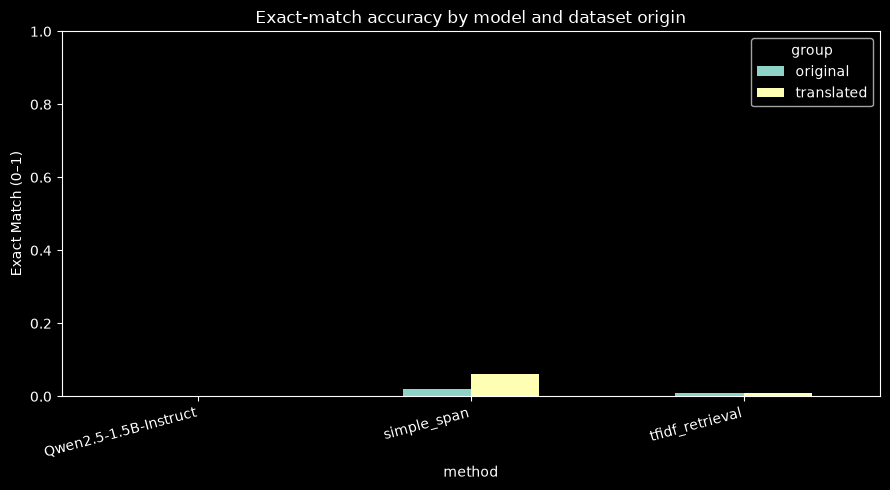

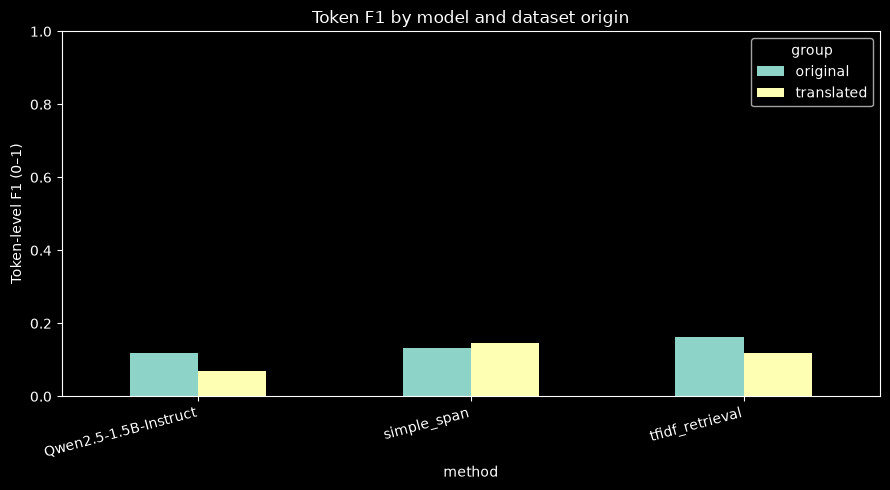

In [21]:
fig,ax=plt.subplots(figsize=(9,5))
summary.pivot(index='method',columns='group',values='EM').plot.bar(ax=ax)
ax.set(ylabel='Exact Match (0–1)',title='Exact-match accuracy by model and dataset origin',ylim=(0,1))
plt.xticks(rotation=15,ha='right');plt.tight_layout()
fig.savefig(OUT/'figure1_em_comparison.png',dpi=180);plt.show()

fig,ax=plt.subplots(figsize=(9,5))
summary.pivot(index='method',columns='group',values='F1').plot.bar(ax=ax)
ax.set(ylabel='Token-level F1 (0–1)',title='Token F1 by model and dataset origin',ylim=(0,1))
plt.xticks(rotation=15,ha='right');plt.tight_layout()
fig.savefig(OUT/'figure2_f1_comparison.png',dpi=180);plt.show()


In [24]:
from pathlib import Path

folder = Path("assignment4_final")

print("Folder exists:", folder.exists())

if folder.exists():
    for file in folder.iterdir():
        print(file.name)

Folder exists: True
appendix_B_error_review_TO_COMPLETE.csv
baseline_predictions.csv
figure1_em_comparison.png
figure2_f1_comparison.png
main_results_table.csv
predictions.json
predictions.partial.json
preparation.json
run_manifest.json
sample_review.csv
selected.json
statistical_results.json
subgroup_analysis.csv


In [26]:
import pandas as pd

results = pd.read_csv(
    "assignment4_final/main_results_table.csv"
)

print(results.to_string(index=False))

               method      group   n   EM       F1
Qwen2.5-1.5B-Instruct   original 100 0.00 0.118745
Qwen2.5-1.5B-Instruct translated 100 0.00 0.070548
          simple_span   original 100 0.02 0.132833
          simple_span translated 100 0.06 0.145548
      tfidf_retrieval   original 100 0.01 0.162437
      tfidf_retrieval translated 100 0.01 0.119524


## 10. Error analysis and subgroup analysis

In [22]:
errors=main[main.exact_match==0].copy()
errors=errors.head(min(30,len(errors)))
error_review=errors[['group','id','question','context','references','prediction','exact_match','token_f1']].copy()
for col in ['error_type','possible_cause','manual_comment']:error_review[col]=''
error_review.to_csv(OUT/'appendix_B_error_review_TO_COMPLETE.csv',index=False,encoding='utf-8-sig')
print('Total Qwen EM errors:',int((main.exact_match==0).sum()))
print('Review rows exported:',len(error_review))
print('MANUAL STEP: categorize every exported error; do not claim this review is finished until filled.')
subgroups=main.groupby(['group','answer_type']).agg(n=('exact_match','size'),EM=('exact_match','mean'),F1=('token_f1','mean')).reset_index()
subgroups.to_csv(OUT/'subgroup_analysis.csv',index=False)
print(subgroups.to_string(index=False))


Total Qwen EM errors: 200
Review rows exported: 30
MANUAL STEP: categorize every exported error; do not claim this review is finished until filled.
     group answer_type  n  EM       F1
  original        long  3 0.0 0.117647
  original      number 13 0.0 0.178708
  original       short 84 0.0 0.109504
translated        long  3 0.0 0.175439
translated      number 13 0.0 0.114305
translated       short 84 0.0 0.060030


In [1]:

from pathlib import Path
import json
import importlib.util

OUT = Path.home() / "Downloads" / "assignment4_final"

selected_path = OUT / "selected.json"

if selected_path.exists():
    selected = json.loads(
        selected_path.read_text(encoding="utf-8")
    )
    print("Dataset found!")
    print("Total questions:", len(selected))
    print("Original:", sum(r["group"] == "original" for r in selected))
    print("Translated:", sum(r["group"] == "translated" for r in selected))
else:
    print("Dataset not found:", selected_path)

print("PyTorch installed:", importlib.util.find_spec("torch") is not None)
print("Transformers installed:", importlib.util.find_spec("transformers") is not None)


Dataset found!
Total questions: 200
Original: 100
Translated: 100
PyTorch installed: True
Transformers installed: True


## XLM-R


In [2]:

import torch
import transformers
from huggingface_hub import model_info

MODEL_XLMR = "deepset/xlm-roberta-large-squad2"

print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("GPU available:", torch.cuda.is_available())

try:
    info = model_info(MODEL_XLMR)
    print("XLM-R model found!")
    print("Model:", MODEL_XLMR)
    print("Revision:", info.sha)
except Exception as e:
    print("Model check failed:", str(e))


C:\Users\User\PycharmProjects\JupyterProject5\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.15.0+cpu
Transformers: 5.22.2
GPU available: False
XLM-R model found!
Model: deepset/xlm-roberta-large-squad2
Revision: dafe59921a75cdffc06ed3ad6e45c581b22b85cc


In [4]:
%pip install --force-reinstall "transformers==4.57.6" "huggingface-hub>=0.34,<1"

  Using cached transformers-4.57.6-py3-none-any.whl.metadata (43 kB)
  Using cached huggingface_hub-0.36.2-py3-none-any.whl.metadata (15 kB)
  Using cached filelock-4.2.9-py3-none-any.whl.metadata (2.3 kB)
  Using cached numpy-2.5.4-cp312-cp312-win_amd64.whl.metadata (6.6 kB)
  Using cached packaging-26.3-py3-none-any.whl.metadata (3.5 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl.metadata (2.4 kB)
  Using cached regex-2026.11.7-cp312-cp312-win_amd64.whl.metadata (41 kB)
  Using cached requests-2.34.2-py3-none-any.whl.metadata (4.8 kB)
  Using cached tokenizers-0.22.2-cp39-abi3-win_amd64.whl.metadata (7.4 kB)
  Using cached safetensors-0.8.0-cp310-abi3-win_amd64.whl.metadata (4.2 kB)
  Using cached tqdm-4.70.1-py3-none-any.whl.metadata (57 kB)
  Using cached fsspec-2026.9.0-py3-none-any.whl.metadata (10 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached colorama-0.4.6-py2.py3-none-any.whl.metadata (17 kB)
  Using cached charset_nor

  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.
  You can safely remove it manually.

[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import transformers
print(transformers.__version__)

4.57.6


In [7]:
%pip install sentencepiece

   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------ --------------------------------- 0.3/1.7 MB ? eta -:--:--
   ------------ --------------------------- 0.5/1.7 MB 929.6 kB/s eta 0:00:02
   ------------ --------------------------- 0.5/1.7 MB 929.6 kB/s eta 0:00:02
   ------------------- -------------------- 0.8/1.7 MB 729.2 kB/s eta 0:00:02
   ------------------------- -------------- 1.0/1.7 MB 751.1 kB/s eta 0:00:01
   ------------------------- -------------- 1.0/1.7 MB 751.1 kB/s eta 0:00:01
   ------------------------- -------------- 1.0/1.7 MB 751.1 kB/s eta 0:00:01
   ------------------------------- -------- 1.3/1.7 MB 664.1 kB/s eta 0:00:01
   ------------------------------- -------- 1.3/1.7 MB 664.1 kB/s eta 0:00:01
   -------------------------------------- - 1.6/1.7 MB 607.7 kB/s eta 0:00:01
   -------------------


[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
%pip install protobuf sentencepiece

  Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl.metadata (595 bytes)
Using cached protobuf-7.36.2-cp310-abi3-win_amd64.whl (456 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
from transformers import AutoTokenizer

MODEL_XLMR = "deepset/xlm-roberta-large-squad2"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_XLMR,
    use_fast=False
)

print("Tokenizer loaded successfully!")
print("Tokenizer:", type(tokenizer).__name__)

Tokenizer loaded successfully!
Tokenizer: XLMRobertaTokenizer


In [1]:

from transformers import (
    AutoTokenizer,
    AutoModelForQuestionAnswering,
    pipeline
)

MODEL_XLMR = "deepset/xlm-roberta-large-squad2"
REVISION = "dafe59921a75cdffc06ed3ad6e45c581b22b85cc"

print("Loading tokenizer...")
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_XLMR,
    revision=REVISION
)

print("Loading model...")
model = AutoModelForQuestionAnswering.from_pretrained(
    MODEL_XLMR,
    revision=REVISION
)

reader = pipeline(
    "question-answering",
    model=model,
    tokenizer=tokenizer,
    device=-1
)

test = {
    "question": "Қазақстанның астанасы қай қала?",
    "context": "Қазақстанның астанасы — Астана қаласы."
}

result = reader(
    question=test["question"],
    context=test["context"]
)

print("Predicted answer:", result["answer"])
print("Confidence score:", result["score"])
print("XLM-R test completed!")


C:\Users\User\PycharmProjects\JupyterProject5\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading tokenizer...


Some weights of the model checkpoint at deepset/xlm-roberta-large-squad2 were not used when initializing XLMRobertaForQuestionAnswering: ['roberta.pooler.dense.bias', 'roberta.pooler.dense.weight']
- This IS expected if you are initializing XLMRobertaForQuestionAnswering from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing XLMRobertaForQuestionAnswering from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).
Device set to use cpu


Loading model...
Predicted answer:  Астана
Confidence score: 0.7332985997200012
XLM-R test completed!


In [2]:

test_examples = [
    {
        "question": "Қазақстанның астанасы қай қала?",
        "context": "Қазақстанның астанасы — Астана қаласы."
    },
    {
        "question": "Абай Құнанбайұлы қай жылы дүниеге келді?",
        "context": "Абай Құнанбайұлы 1845 жылы дүниеге келген."
    },
    {
        "question": "Қазақстанның мемлекеттік тілі қандай?",
        "context": "Қазақстан Республикасының мемлекеттік тілі — қазақ тілі."
    }
]

for i, example in enumerate(test_examples, 1):
    result = reader(
        question=example["question"],
        context=example["context"]
    )

    print(f"Question {i}: {example['question']}")
    print(f"Prediction: {result['answer']}")
    print(f"Confidence: {result['score']:.4f}")
    print("-" * 40)


Question 1: Қазақстанның астанасы қай қала?
Prediction:  Астана
Confidence: 0.7333
----------------------------------------
Question 2: Абай Құнанбайұлы қай жылы дүниеге келді?
Prediction:  1845
Confidence: 0.9158
----------------------------------------
Question 3: Қазақстанның мемлекеттік тілі қандай?
Prediction:  қазақ тілі.
Confidence: 0.5678
----------------------------------------


In [3]:
from pathlib import Path
import json
import torch

OUT = Path.home() / "Downloads" / "assignment4_final"

selected = json.loads(
    (OUT / "selected.json").read_text(encoding="utf-8")
)

assert len(selected) == 200
assert sum(r["group"] == "original" for r in selected) == 100
assert sum(r["group"] == "translated" for r in selected) == 100

print("Dataset: READY")
print("XLM-R model: READY" if reader is not None else "NOT READY")
print("Device:", "GPU" if torch.cuda.is_available() else "CPU")
print("Existing Qwen results:",
      (OUT / "predictions.json").exists())
print("Existing XLM-R results:",
      (OUT / "xlmr_predictions.csv").exists())

print("Preparation completed. No final evaluation performed.")


Dataset: READY
XLM-R model: READY
Device: CPU
Existing Qwen results: True
Existing XLM-R results: False
Preparation completed. No final evaluation performed.


In [6]:

import json
import pandas as pd
from pathlib import Path
from tqdm.auto import tqdm

OUT = Path.home() / "Downloads" / "assignment4_final"

selected = json.loads(
    (OUT / "selected.json").read_text(encoding="utf-8")
)

results_path = OUT / "xlmr_predictions.csv"

if results_path.exists():
    raise FileExistsError(
        "XLM-R results already exist. Do not overwrite them."
    )

xlmr_results = []

for row in tqdm(selected, desc="XLM-R evaluation"):
    result = reader(
        question=row["question"],
        context=row["context"],
        max_answer_len=30,
        handle_impossible_answer=False
    )

    prediction = result["answer"].strip()
    em, f1 = score(prediction, row["references"])

    xlmr_results.append({
        "group": row["group"],
        "id": row["id"],
        "prediction": prediction,
        "exact_match": em,
        "token_f1": f1,
        "confidence": result["score"]
    })

    pd.DataFrame(xlmr_results).to_csv(
        OUT / "xlmr_predictions.partial.csv",
        index=False,
        encoding="utf-8-sig"
    )

pd.DataFrame(xlmr_results).to_csv(
    results_path,
    index=False,
    encoding="utf-8-sig"
)

summary = (
    pd.DataFrame(xlmr_results)
    .groupby("group")[["exact_match", "token_f1"]]
    .mean()
)

print("XLM-R experiment completed!")
print(summary)
print("Saved to:", results_path)


XLM-R evaluation: 100%|██████████| 200/200 [02:30<00:00,  1.33it/s]

XLM-R experiment completed!
            exact_match  token_f1
group                            
original            0.4  0.561059
translated          0.3  0.423687
Saved to: C:\Users\User\Downloads\assignment4_final\xlmr_predictions.csv


In [5]:

import collections
import unicodedata

def normalise(text):
    text = unicodedata.normalize("NFC", str(text)).casefold()
    text = "".join(
        " " if unicodedata.category(c).startswith("P") else c
        for c in text
    )
    return " ".join(text.split())

def score(prediction, references):
    p = normalise(prediction).split()
    em, f1 = 0.0, 0.0

    for reference in references:
        r = normalise(reference).split()

        em = max(em, float(p == r))

        overlap = sum(
            (collections.Counter(p) & collections.Counter(r)).values()
        )

        value = (
            2 * overlap / (len(p) + len(r))
            if p and r
            else float(p == r)
        )

        f1 = max(f1, value)

    return em, f1

print("Scoring function is ready!")
print("Test:", score("Астана", ["Астана"]))


Scoring function is ready!
Test: (1.0, 1.0)


## Final Model Comparison

Data validation passed: 200 matched questions

========== MAIN RESULTS ==========
       Model      Group   N  Exact_Match  Token_F1
Qwen2.5-1.5B   original 100          0.0  0.118745
Qwen2.5-1.5B translated 100          0.0  0.070548
 XLM-R-large   original 100          0.4  0.561059
 XLM-R-large translated 100          0.3  0.423687

========== STATISTICAL COMPARISON ==========
     Group  Qwen_only_correct  XLMR_only_correct  McNemar_exact_p  EM_difference  F1_difference  F1_CI95_lower  F1_CI95_upper  McNemar_p_Holm
  original                  0                 40     1.818989e-12            0.4       0.442314       0.355902       0.529376    3.637979e-12
translated                  0                 30     1.862645e-09            0.3       0.353139       0.266765       0.440650    1.862645e-09


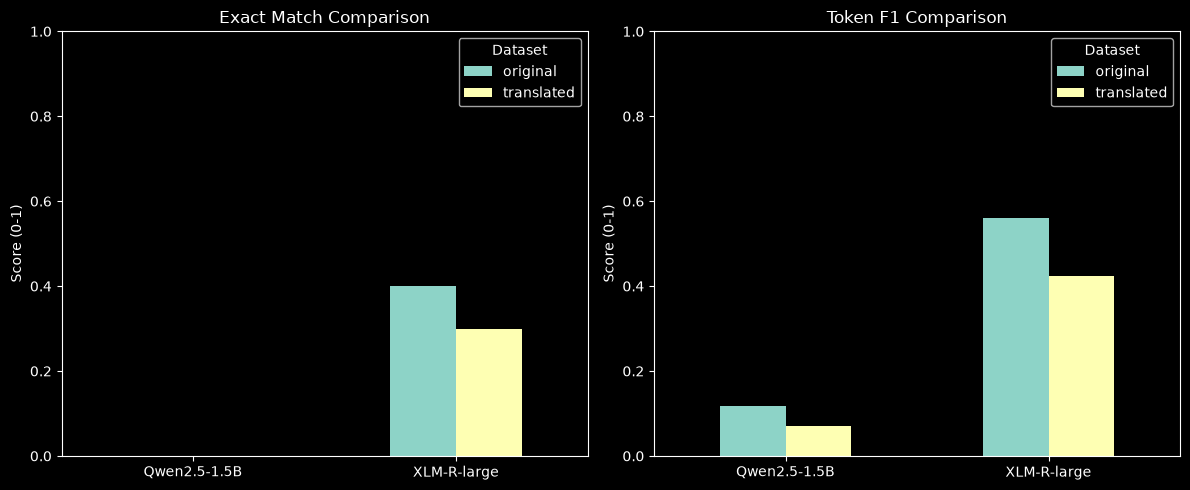


COMPLETED SUCCESSFULLY!
Saved files:
1. final_model_comparison.csv
2. final_statistical_comparison.csv
3. final_qwen_vs_xlmr.png

Folder: C:\Users\User\Downloads\assignment4_final


In [9]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binomtest

# ==========================================
# Assignment 4: Final Model Comparison
# ==========================================

OUT = Path.home() / "Downloads" / "assignment4_final"
OUT.mkdir(parents=True, exist_ok=True)

# 1. Load saved predictions
qwen_path = OUT / "predictions.json"
xlmr_path = OUT / "xlmr_predictions.csv"

assert qwen_path.exists(), "Qwen predictions.json not found"
assert xlmr_path.exists(), "XLM-R predictions.csv not found"

qwen = pd.DataFrame(
    json.loads(qwen_path.read_text(encoding="utf-8"))
)
xlmr = pd.read_csv(xlmr_path, encoding="utf-8-sig")

keys = ["group", "id"]
metrics = ["exact_match", "token_f1"]

# 2. Validate datasets
for name, df in [("Qwen", qwen), ("XLM-R", xlmr)]:

    df["group"] = df["group"].astype(str)
    df["id"] = df["id"].astype(str)

    assert len(df) == 200, f"{name}: expected 200 rows"

    assert not df.duplicated(keys).any(), (
        f"{name}: duplicate questions"
    )

    counts = df.groupby("group").size().to_dict()

    assert counts == {
        "original": 100,
        "translated": 100
    }, f"{name}: incorrect group sizes"

    for metric in metrics:
        df[metric] = pd.to_numeric(
            df[metric], errors="raise"
        )

    assert df[metrics].notna().all().all(), (
        f"{name}: missing metric values"
    )

    # Correct DataFrame range check
    valid = (
        (df[metrics] >= 0) &
        (df[metrics] <= 1)
    )

    assert valid.all().all(), (
        f"{name}: metrics outside [0, 1]"
    )

qwen_keys = set(map(tuple, qwen[keys].values))
xlmr_keys = set(map(tuple, xlmr[keys].values))

assert qwen_keys == xlmr_keys, (
    "Qwen and XLM-R used different test questions!"
)

print("Data validation passed: 200 matched questions")

# 3. Pair predictions
paired = qwen[keys + metrics].merge(
    xlmr[keys + metrics],
    on=keys,
    suffixes=("_qwen", "_xlmr"),
    validate="one_to_one"
)

assert len(paired) == 200

# 4. Main results
summary_rows = []

for model_name, df in [
    ("Qwen2.5-1.5B", qwen),
    ("XLM-R-large", xlmr)
]:
    for group, subset in df.groupby("group"):
        summary_rows.append({
            "Model": model_name,
            "Group": group,
            "N": len(subset),
            "Exact_Match": subset["exact_match"].mean(),
            "Token_F1": subset["token_f1"].mean()
        })

summary = pd.DataFrame(summary_rows)

print("\n========== MAIN RESULTS ==========")
print(summary.to_string(index=False))

summary.to_csv(
    OUT / "final_model_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# 5. Statistical comparison
rng = np.random.default_rng(42)
stat_rows = []

for group, subset in paired.groupby("group"):

    q = subset["exact_match_qwen"].to_numpy()
    x = subset["exact_match_xlmr"].to_numpy()

    q_only = int(
        ((q == 1) & (x == 0)).sum()
    )

    x_only = int(
        ((q == 0) & (x == 1)).sum()
    )

    discordant = q_only + x_only

    if discordant > 0:
        p_value = binomtest(
            q_only,
            discordant,
            p=0.5,
            alternative="two-sided"
        ).pvalue
    else:
        p_value = 1.0

    # Paired bootstrap for token F1 difference
    differences = (
        subset["token_f1_xlmr"].to_numpy()
        - subset["token_f1_qwen"].to_numpy()
    )

    bootstrap_means = np.array([
        rng.choice(
            differences,
            size=len(differences),
            replace=True
        ).mean()
        for _ in range(2000)
    ])

    lower, upper = np.quantile(
        bootstrap_means,
        [0.025, 0.975]
    )

    stat_rows.append({
        "Group": group,
        "Qwen_only_correct": q_only,
        "XLMR_only_correct": x_only,
        "McNemar_exact_p": p_value,
        "EM_difference": x.mean() - q.mean(),
        "F1_difference": differences.mean(),
        "F1_CI95_lower": lower,
        "F1_CI95_upper": upper
    })

stats = pd.DataFrame(stat_rows)

# 6. Holm correction
pvals = stats["McNemar_exact_p"].to_numpy()
order = np.argsort(pvals)

adjusted = np.zeros(len(pvals))
running = 0.0

for rank, index in enumerate(order):
    running = max(
        running,
        min(1.0, (len(pvals) - rank) * pvals[index])
    )
    adjusted[index] = running

stats["McNemar_p_Holm"] = adjusted

print("\n========== STATISTICAL COMPARISON ==========")
print(stats.to_string(index=False))

stats.to_csv(
    OUT / "final_statistical_comparison.csv",
    index=False,
    encoding="utf-8-sig"
)

# 7. Create comparison figure
fig, axes = plt.subplots(
    1, 2,
    figsize=(12, 5)
)

for ax, metric, title in zip(
    axes,
    ["Exact_Match", "Token_F1"],
    ["Exact Match Comparison", "Token F1 Comparison"]
):

    pivot = summary.pivot(
        index="Model",
        columns="Group",
        values=metric
    )

    pivot.plot(
        kind="bar",
        ax=ax
    )

    ax.set_title(title)
    ax.set_ylabel("Score (0-1)")
    ax.set_ylim(0, 1)
    ax.set_xlabel("")
    ax.tick_params(
        axis="x",
        rotation=0
    )
    ax.legend(title="Dataset")

plt.tight_layout()

figure_path = OUT / "final_qwen_vs_xlmr.png"

plt.savefig(
    figure_path,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\n================================")
print("COMPLETED SUCCESSFULLY!")
print("================================")
print("Saved files:")
print("1. final_model_comparison.csv")
print("2. final_statistical_comparison.csv")
print("3. final_qwen_vs_xlmr.png")
print("\nFolder:", OUT)
